# 10 · Correlate local orientation across space

Let g = gₓ + igᵧ be the periodic central-difference gradient. Over an 8 × 8 sliding window, define $z(r)=\langle g^2/|g|\rangle/\langle|g|\rangle$, taking zero when the denominator vanishes. This is the local magnitude-weighted nematic moment m₂. The trace correlation is $C_Q(\delta)=\operatorname{Re}\langle z(r)\overline{z(r+\delta)}\rangle$; apart from a factor 1/2, it contracts the local Q tensors.

## Setup
Stage 2 holds the motif inventory fixed and changes spatial organization.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.fft import dctn
from observables.core import moments,relative_distance
from observables.images import tiled_orientation
from observables.spatial import *
OUT=ROOT/'results'/'stage2'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.figsize':(8,3.8),'figure.dpi':110,
 'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
images={name:mosaic(name) for name in LAYOUTS}
gallery=[representations(image) for image in images.values()]

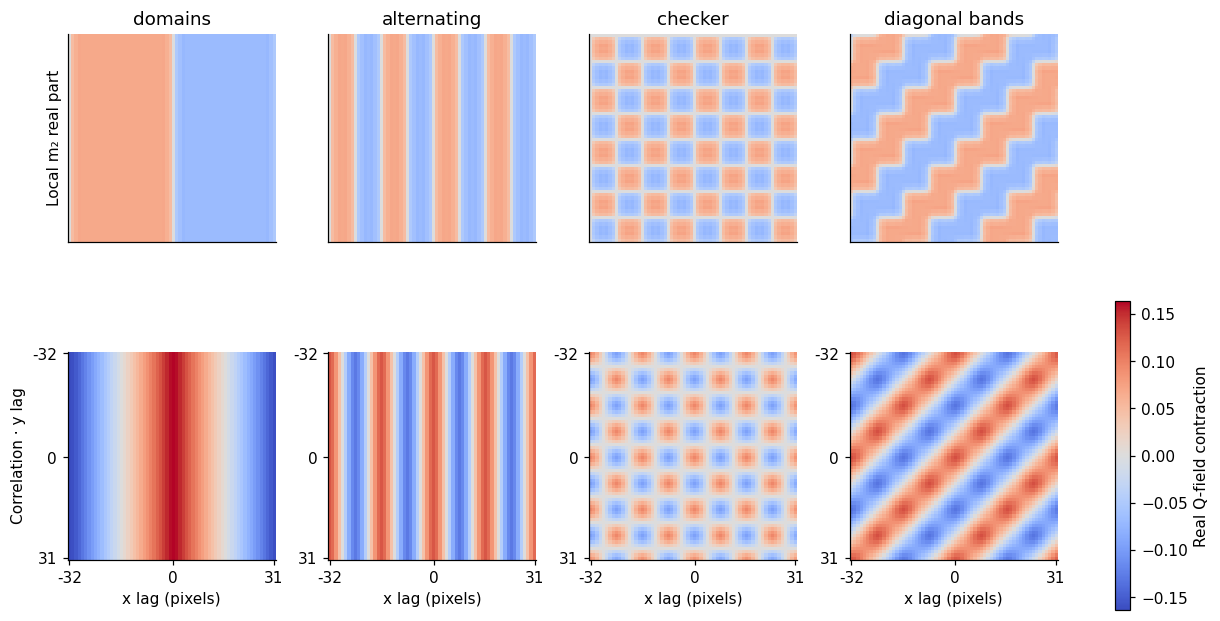

In [3]:
limit=max(np.max(np.abs(q_correlation(q_field(a)))) for a in images.values())
fig,axes=plt.subplots(2,4,figsize=(11,5.8))
for col,(name,a) in enumerate(images.items()):
    z=q_field(a);corr=q_correlation(z)
    axes[0,col].imshow(z.real,cmap='coolwarm',vmin=-1,vmax=1)
    im=axes[1,col].imshow(np.fft.fftshift(corr),cmap='coolwarm',vmin=-limit,vmax=limit)
    axes[0,col].set_title(name)
    axes[0,col].set_xticks([]);axes[0,col].set_yticks([])
    axes[1,col].set_xticks([0,32,63],[-32,0,31]);axes[1,col].set_yticks([0,32,63],[-32,0,31])
axes[0,0].set_ylabel('Local m₂ real part')
axes[1,0].set_ylabel('Correlation · y lag')
for ax in axes[1]:ax.set_xlabel('x lag (pixels)')
fig.colorbar(im,ax=axes[1],label='Real Q-field contraction')
show('10_Q_fields_correlations')

## Translation invariance with an explicit cost
Comparing correlation maps removes absolute position. Comparing the Q-fields after minimizing over translations removes that nuisance while retaining more phase information. The orbit search uses FFT cross-correlation to evaluate every integer displacement. It makes the same search available to every candidate.

Unregistered Q-field distance 0.5766207462413471
Registered Q-field distance 0.0
Correlation distance 4.0632970796509646e-16


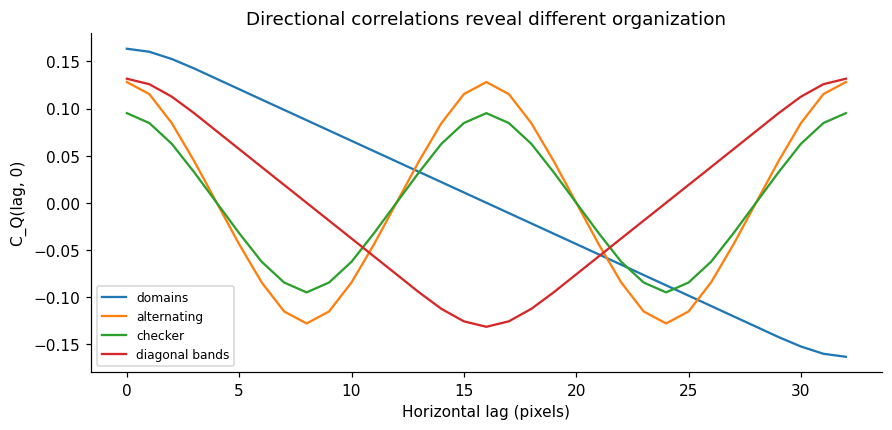

In [5]:
a=images['domains'];b=-np.roll(a,(3,11),(0,1))
za,zb=q_field(a),q_field(b)
print('Unregistered Q-field distance',relative_distance(za,zb))
print('Registered Q-field distance',orbit_distance(za,zb))
print('Correlation distance',relative_distance(q_correlation(za),q_correlation(zb)))
np.testing.assert_allclose(q_correlation(za),q_correlation(zb),atol=1e-12)
fig,ax=plt.subplots()
for name,a in images.items():
    c=q_correlation(q_field(a))
    ax.plot(np.arange(33),c[0,:33],label=name)
ax.set(xlabel='Horizontal lag (pixels)',ylabel='C_Q(lag, 0)',title='Directional correlations reveal different organization')
ax.legend(fontsize=8);show('10_directional_correlations')

## Group action and rotation
A physical quarter turn rotates coordinates and rotates gradient directions. The nematic phase changes by $e^{2i\alpha}$, so a 90° turn contributes a sign. The implementation recomputes descriptors from each of the four rotated images, ensuring both transformations are included. Correlation comparison minimizes over those four rotations. Q-field registration also searches all integer translations. Pixel registration additionally permits global contrast reversal.

Even-sized averaging windows have an origin convention. Recomputing the field after each image rotation handles that convention directly; the translation orbit handles resulting origin offsets.

In [7]:
a=images['diagonal bands'];b=-np.rot90(np.roll(a,(5,9),(0,1)))
scores=candidate_distances(b,gallery)
display(pd.DataFrame({key:values for key,values in scores.items() if key in ['whole_Q','Q_correlation','registered_Q','registered_pixels']},index=LAYOUTS).round(6))
for name in ['Q_correlation','registered_Q','registered_pixels']:
    assert np.argmin(scores[name])==3

,whole_Q,Q_correlation,registered_Q,registered_pixels
domains,0.999693,0.713358,0.708138,0.485913
alternating,0.999693,0.708644,0.707116,0.485913
checker,0.999693,0.732855,0.707671,0.485913
diagonal bands,0.999693,0.000000,0.000000,0.000000


## Failure modes to retain
Two different Q-fields can share a trace correlation. The homometric construction in Notebook 04 remains a warning about pair-information loss. In addition, mapping gradients to local m₂ removes polarity and may erase orientation mixtures. A claim of full reconstruction would require extra assumptions and richer observables.